# EDA e seleção de features para risco por H3

Análise do período de treino janeiro/2023–junho/2025 para CRIME, FURTO e ROUBO. Linhas de 2022 não entram no treino; podem ser usadas como contexto histórico para gerar as features anteriores a 2023.

## Definição do risco e relação entre os alvos

O score de intensidade usado aqui é `contagem / (contagem + K)`, em que `K` é o percentil 90 das contagens positivas no período de treino, estimado separadamente para cada alvo. O score é 0 quando não há ocorrência, cresce monotonicamente e se aproxima de 1 sem corte rígido por máximo. Como todo score limitado, ele ainda comprime aumentos extremos; por isso, mantenho também as contagens e recomendo modelá-las (ou `log1p(contagem)`) quando a prioridade for prever volume.

Antes da seleção, verificar se `CNT_CRIME_COUNT = FURTO_COUNT + ROUBO_COUNT` em cada H3/mês. Se isso for verdadeiro, não usar furto/roubo do mês corrente como preditores do crime. Os históricos dos meses anteriores são disponíveis no momento da previsão, mas podem ser redundantes com o histórico de crime e serão avaliados por ablação.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor
from pathlib import Path

source_path = Path('../datasets/database_processed_h3_final.csv')
risk_path = Path('../datasets/database_processed_h3_risk.csv')
df = pd.read_csv(source_path, parse_dates=['DATA'], low_memory=False)
train_start, train_end = '2023-01-01', '2025-06-01'
train_mask = df.DATA.between(train_start, train_end)
count_to_target = {'CNT_CRIME':'RISCO_CRIME','FURTO':'RISCO_FURTO','ROUBO':'RISCO_ROUBO'}
scales = {c: float(df.loc[train_mask & df[c].gt(0),c].quantile(.90)) for c in count_to_target}
for count_col, target in count_to_target.items():
    k = scales[count_col]
    df[target] = df[count_col].clip(lower=0) / (df[count_col].clip(lower=0) + k)
    df.rename(columns={count_col: f'{count_col}_COUNT'}, inplace=True)
df['MES_SIN'] = np.sin(2*np.pi*df.DATA.dt.month/12)
df['MES_COS'] = np.cos(2*np.pi*df.DATA.dt.month/12)
for out_col, count_col in {'pct_dom_casa':'dom_casa','pct_dom_apartamento':'dom_apartamento','pct_dom_cortico':'dom_cortico','pct_dom_agua_encanada':'dom_agua_encanada','pct_dom_esgoto_rede':'dom_esgoto_rede','pct_dom_lixo_coletado':'dom_lixo_coletado'}.items():
    df['SEM_DOMICILIOS'] = (df.domicilios_total <= 0).astype('int8')
    df[out_col] = (df[count_col] / df.domicilios_total.where(df.domicilios_total.gt(0))).fillna(0)
targets = list(count_to_target.values())
count_cols = [f'{c}_COUNT' for c in count_to_target]
risk_scales = pd.Series(scales, name='K_p90_contagem_positiva')
df.to_csv(risk_path, index=False)
print('Escalas K:', scales)
print('Base de scores salva:', risk_path.resolve())


Escalas K: {'CNT_CRIME': 155.0, 'FURTO': 106.0, 'ROUBO': 62.0}
Base de scores salva: C:\Users\Usuario\Documents\USP\8_SEMESTRE\Resolução de Problemas II\sp-crime-spatiotemporal-prediction\datasets\database_processed_h3_risk.csv


In [2]:
df_train = df.loc[df.DATA.between(train_start, train_end)].copy()
print('Linhas:',len(df_train),'H3:',df_train.H3.nunique(),'meses:',df_train.DATA.nunique())
print('Duplicatas H3/mês:',df_train.duplicated(['H3','DATA']).sum())


Linhas: 37800 H3: 1260 meses: 30
Duplicatas H3/mês: 0


## Consistência CRIME = FURTO + ROUBO

In [3]:
crime_col, furto_col, roubo_col = 'CNT_CRIME_COUNT','FURTO_COUNT','ROUBO_COUNT'
df_train['soma_componentes'] = df_train[furto_col] + df_train[roubo_col]
df_train['diferenca_crime_componentes'] = df_train[crime_col] - df_train['soma_componentes']
print('Linhas em que CRIME difere de FURTO + ROUBO:',int(df_train.diferenca_crime_componentes.ne(0).sum()))
print('Diferença absoluta máxima:',int(df_train.diferenca_crime_componentes.abs().max()))


Linhas em que CRIME difere de FURTO + ROUBO: 0
Diferença absoluta máxima: 0


## Distribuição e concentração espacial

Concentração é evidência para testar regimes de baixa e alta atividade. A classificação de uma célula como baixa/alta para modelagem precisa usar somente histórico disponível antes da previsão; este resumo retrospectivo serve para diagnóstico, não para atribuir grupos no conjunto de validação.

In [4]:
risk_summary = pd.DataFrame(index=targets)
risk_summary['K_p90_positivos'] = [scales[c] for c in count_to_target]
risk_summary['score_medio'] = df_train[targets].mean()
risk_summary['score_mediano'] = df_train[targets].median()
risk_summary['score_p95'] = df_train[targets].quantile(.95)
risk_summary['pct_zero'] = [df_train[c].eq(0).mean()*100 for c in count_cols]
display(risk_summary.round(3))
cell_concentration = []
for count_col in count_cols:
    totals = df_train.groupby('H3')[count_col].sum().sort_values(ascending=False)
    n_top10 = max(1, int(np.ceil(.10*len(totals))))
    cell_concentration.append({'alvo':count_col,'celulas_sem_ocorrencia':int(totals.eq(0).sum()),'participacao_top_1pct':totals.head(max(1,int(np.ceil(.01*len(totals))))).sum()/totals.sum(),'participacao_top_10pct':totals.head(n_top10).sum()/totals.sum()})
concentration = pd.DataFrame(cell_concentration).set_index('alvo')
concentration[['participacao_top_1pct','participacao_top_10pct']] *= 100
display(concentration.round(2))


,K_p90_positivos,score_medio,score_mediano,score_p95,pct_zero
RISCO_CRIME,155.0,0.108,0.006,0.517,42.690
RISCO_FURTO,106.0,0.102,0.009,0.507,47.399
RISCO_ROUBO,62.0,0.101,0.000,0.492,53.767


,celulas_sem_ocorrencia,participacao_top_1pct,participacao_top_10pct
alvo,,,
CNT_CRIME_COUNT,74,30.04,69.71
FURTO_COUNT,138,34.14,73.53
ROUBO_COUNT,263,22.13,65.20


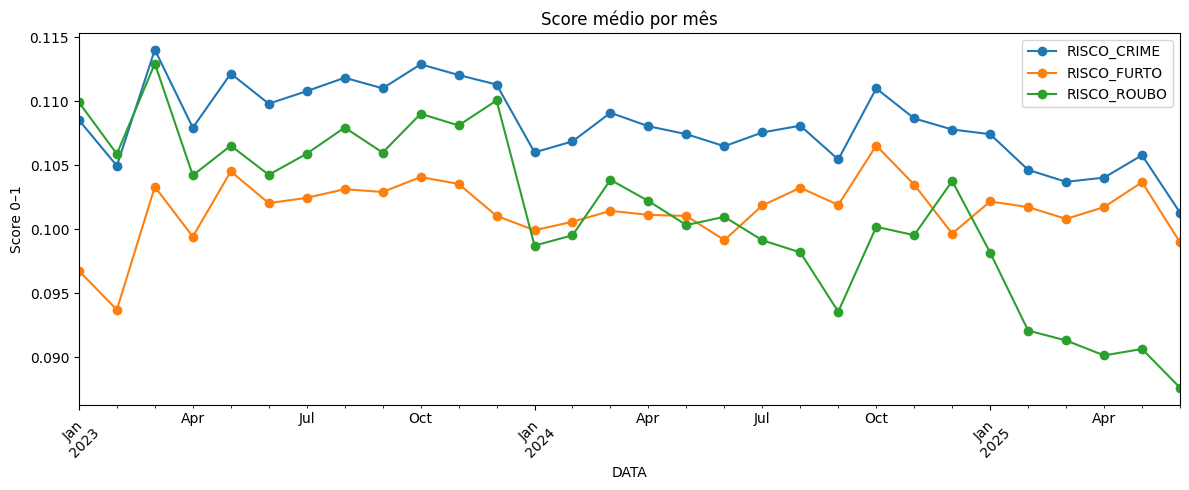

In [5]:
monthly = df_train.groupby(df_train.DATA.dt.to_period('M'))[targets].mean()
monthly.plot(figsize=(12,5),marker='o',title='Score médio por mês'); plt.ylabel('Score 0–1'); plt.xticks(rotation=45); plt.tight_layout(); plt.show()


## Cobertura das features e colinearidade

In [6]:
history_cols = [c for c in df.columns if c.startswith(('crime_','furto_','roubo_'))]
print('Nulos em histórico/vizinhança no treino:',int(df_train[history_cols].isna().sum().sum()))
excluded = set(targets+count_cols+['H3','DATA','N_IPVS','CIDADE','soma_componentes','diferenca_crime_componentes'])
numeric_features = [c for c in df_train.select_dtypes('number').columns if c not in excluded]
quality = pd.DataFrame({'nulos':df_train[numeric_features].isna().sum(),'distintos':df_train[numeric_features].nunique(dropna=False),'std':df_train[numeric_features].std()})
constant = quality.index[quality.distintos<=1].tolist()
numeric_features = [c for c in numeric_features if c not in constant]
print('Features numéricas constantes removidas:',constant)
pearson = df_train[numeric_features].corr().abs()
i,j=np.triu_indices(len(pearson),1)
pairs=pd.DataFrame({'feature_1':pearson.columns[i],'feature_2':pearson.columns[j],'abs_corr':pearson.to_numpy()[i,j]})
display(pairs[pairs.abs_corr>=.90].sort_values('abs_corr',ascending=False))


Nulos em histórico/vizinhança no treino: 0
Features numéricas constantes removidas: ['pop_total_missing', 'domicilios_total_missing', 'media_moradores_missing', 'domicilios_vagos_missing', 'N_IPVS_missing']


,feature_1,feature_2,abs_corr
1819,nao_alfabetizados_15mais_missing,taxa_alfabetizacao_missing,1.000000
1551,pop_masc_missing,alfabetizados_15mais_missing,1.000000
1596,pop_fem_missing,alfabetizados_15mais_missing,0.999999
1547,pop_masc_missing,pop_fem_missing,0.999999
1897,pop_preta_missing,pct_negros_missing,0.998978
...,...,...,...
2462,roubo_media_12m_log,furto_viz_media_3m_log,0.904604
2287,crime_media_12m_log,roubo_pct_meses_12m,0.903583
2386,furto_media_12m_log,roubo_viz_media_3m_log,0.903093
89,pop_total,dom_agua_encanada,0.902866


## Seleção por alvo: correlação, prioridade de domínio e VIF

Método inicial: (1) excluir contagens/alvos contemporâneos e features constantes; (2) manter uma representação por grupo quando `|Pearson| >= 0,90`, priorizando features históricas próprias, depois vizinhança, depois contexto normalizado; (3) calcular VIF no conjunto reduzido e sinalizar valores > 5; (4) consolidar por ablação em validação temporal, retendo variáveis/grupos com ganho estável. A correlação é um filtro, não a seleção final.

In [7]:
context = ['C_IPVS','pop_total','media_moradores','pct_jovens_15_29','taxa_alfabetizacao','pct_negros','pct_dom_casa','pct_dom_apartamento','pct_dom_cortico','pct_dom_agua_encanada','pct_dom_esgoto_rede','pct_dom_lixo_coletado','MES_SIN','MES_COS','SEM_DOMICILIOS']
own_history = ['media_12m_log','razao_3_12','sazonal_12','pct_meses_12m']

def features_for(target_prefix):
    own = [f'{target_prefix}_{suffix}' for suffix in own_history]
    neighborhood = [f'{target_prefix}_viz_media_3m_log', f'{target_prefix}_viz_rel']
    # Past crime history can be tested for component targets, then removed if
    # redundant. Crime uses total-crime history only in the primary candidate.
    cross = ['crime_media_12m_log', 'crime_pct_meses_12m'] if target_prefix in ('furto', 'roubo') else []
    return [col for col in own + neighborhood + cross + context if col in df_train.columns]

def prune_correlated(cols, threshold=0.90):
    kept, dropped = [], []
    for col in cols:
        if df_train[col].nunique(dropna=False) <= 1:
            continue
        conflict = next((k for k in kept if abs(df_train[[k, col]].corr().iloc[0, 1]) >= threshold), None)
        if conflict:
            dropped.append((col, conflict, df_train[[col, conflict]].corr().iloc[0, 1]))
        else:
            kept.append(col)
    return kept, dropped

def vif_table(cols):
    X = df_train[cols].replace([np.inf, -np.inf], np.nan).dropna()
    X = X.loc[:, X.nunique() > 1]
    if X.shape[1] < 2:
        return pd.DataFrame(columns=['feature', 'VIF'])
    X = (X - X.mean()) / X.std(ddof=0)
    values = [variance_inflation_factor(X.to_numpy(), i) for i in range(X.shape[1])]
    return pd.DataFrame({'feature': X.columns, 'VIF': values}).sort_values('VIF', ascending=False)


In [8]:
selected_candidates={}
for prefix,target in [('crime','RISCO_CRIME'),('furto','RISCO_FURTO'),('roubo','RISCO_ROUBO')]:
    cols=features_for(prefix); kept,dropped=prune_correlated(cols)
    vif_removed=[]
    while len(kept)>2:
        current_vif=vif_table(kept)
        if current_vif.empty or current_vif.VIF.max()<=5: break
        worst=current_vif.iloc[0]
        vif_removed.append((worst.feature,round(worst.VIF,2)))
        kept.remove(worst.feature)
    selected_candidates[target]=kept
    print('\n',target,'candidatas finais após |r|<0.90 e VIF<=5:',kept)
    print('Removidas por |r|>=0.90 (feature, representante, rho):',dropped)
    print('Removidas iterativamente por VIF:',vif_removed)
    display(vif_table(kept))



 RISCO_CRIME candidatas finais após |r|<0.90 e VIF<=5: ['crime_media_12m_log', 'crime_razao_3_12', 'crime_sazonal_12', 'crime_pct_meses_12m', 'crime_viz_rel', 'C_IPVS', 'pop_total', 'media_moradores', 'pct_jovens_15_29', 'taxa_alfabetizacao', 'pct_negros', 'pct_dom_casa', 'pct_dom_apartamento', 'pct_dom_cortico', 'MES_SIN', 'MES_COS', 'SEM_DOMICILIOS']
Removidas por |r|>=0.90 (feature, representante, rho): [('crime_viz_media_3m_log', 'crime_media_12m_log', 0.9161670632967291), ('pct_dom_agua_encanada', 'pct_dom_casa', 0.9951633119650414), ('pct_dom_esgoto_rede', 'pct_dom_casa', 0.9900993423542599), ('pct_dom_lixo_coletado', 'pct_dom_casa', 0.9524141659616941)]
Removidas iterativamente por VIF: []


,feature,VIF
0,crime_media_12m_log,4.102089
3,crime_pct_meses_12m,3.826398
11,pct_dom_casa,2.472774
5,C_IPVS,2.444445
10,pct_negros,2.234785
9,taxa_alfabetizacao,2.162021
12,pct_dom_apartamento,2.095397
7,media_moradores,2.045958
8,pct_jovens_15_29,1.865043
6,pop_total,1.582363



 RISCO_FURTO candidatas finais após |r|<0.90 e VIF<=5: ['furto_media_12m_log', 'furto_razao_3_12', 'furto_sazonal_12', 'furto_pct_meses_12m', 'furto_viz_rel', 'C_IPVS', 'pop_total', 'media_moradores', 'pct_jovens_15_29', 'taxa_alfabetizacao', 'pct_negros', 'pct_dom_casa', 'pct_dom_apartamento', 'pct_dom_cortico', 'MES_SIN', 'MES_COS', 'SEM_DOMICILIOS']
Removidas por |r|>=0.90 (feature, representante, rho): [('furto_viz_media_3m_log', 'furto_media_12m_log', 0.9063091838733329), ('crime_media_12m_log', 'furto_media_12m_log', 0.9933450073998527), ('crime_pct_meses_12m', 'furto_pct_meses_12m', 0.9724975859171503), ('pct_dom_agua_encanada', 'pct_dom_casa', 0.9951633119650414), ('pct_dom_esgoto_rede', 'pct_dom_casa', 0.9900993423542599), ('pct_dom_lixo_coletado', 'pct_dom_casa', 0.9524141659616941)]
Removidas iterativamente por VIF: []


,feature,VIF
0,furto_media_12m_log,4.700727
3,furto_pct_meses_12m,4.524547
11,pct_dom_casa,2.474302
5,C_IPVS,2.438612
10,pct_negros,2.237785
9,taxa_alfabetizacao,2.149115
12,pct_dom_apartamento,2.094546
7,media_moradores,2.049399
8,pct_jovens_15_29,1.852529
6,pop_total,1.605765



 RISCO_ROUBO candidatas finais após |r|<0.90 e VIF<=5: ['roubo_media_12m_log', 'roubo_razao_3_12', 'roubo_sazonal_12', 'roubo_viz_rel', 'C_IPVS', 'pop_total', 'media_moradores', 'pct_jovens_15_29', 'taxa_alfabetizacao', 'pct_negros', 'pct_dom_casa', 'pct_dom_apartamento', 'pct_dom_cortico', 'MES_SIN', 'MES_COS', 'SEM_DOMICILIOS']
Removidas por |r|>=0.90 (feature, representante, rho): [('roubo_viz_media_3m_log', 'roubo_media_12m_log', 0.9328189977656376), ('crime_media_12m_log', 'roubo_media_12m_log', 0.9856700690324394), ('crime_pct_meses_12m', 'roubo_pct_meses_12m', 0.9290428798746365), ('pct_dom_agua_encanada', 'pct_dom_casa', 0.9951633119650414), ('pct_dom_esgoto_rede', 'pct_dom_casa', 0.9900993423542599), ('pct_dom_lixo_coletado', 'pct_dom_casa', 0.9524141659616941)]
Removidas iterativamente por VIF: [('roubo_pct_meses_12m', 5.68)]


,feature,VIF
10,pct_dom_casa,2.468476
4,C_IPVS,2.427120
9,pct_negros,2.168577
11,pct_dom_apartamento,2.094260
8,taxa_alfabetizacao,2.079227
6,media_moradores,2.043941
0,roubo_media_12m_log,1.847551
7,pct_jovens_15_29,1.820339
5,pop_total,1.527677
15,SEM_DOMICILIOS,1.304516


## Evidência de associação por alvo

In [9]:
for target in targets:
    cols=[c for c in numeric_features if c in df_train]
    rho=df_train[cols].corrwith(df_train[target],method='spearman').dropna()
    display(rho.reindex(rho.abs().sort_values(ascending=False).index).head(15).rename('rho_spearman').to_frame().style.set_caption(target))


,rho_spearman
crime_media_12m_log,0.917830
furto_media_12m_log,0.912874
roubo_media_12m_log,0.909280
roubo_pct_meses_12m,0.887357
furto_pct_meses_12m,0.881806
crime_pct_meses_12m,0.872161
crime_viz_media_3m_log,0.840148
roubo_viz_media_3m_log,0.839853
furto_viz_media_3m_log,0.833351
dom_apartamento,0.779338


,rho_spearman
furto_media_12m_log,0.900076
crime_media_12m_log,0.897809
roubo_media_12m_log,0.882507
furto_pct_meses_12m,0.865109
roubo_pct_meses_12m,0.859178
crime_pct_meses_12m,0.845899
crime_viz_media_3m_log,0.821970
furto_viz_media_3m_log,0.819245
roubo_viz_media_3m_log,0.816009
dom_apartamento,0.775916


,rho_spearman
roubo_media_12m_log,0.890095
crime_media_12m_log,0.877893
furto_media_12m_log,0.866291
roubo_pct_meses_12m,0.864011
roubo_viz_media_3m_log,0.833101
furto_pct_meses_12m,0.829473
crime_viz_media_3m_log,0.824242
crime_pct_meses_12m,0.818944
furto_viz_media_3m_log,0.813666
dom_apartamento,0.762158


## Como testar a hipótese de dois grupos

No período, os 10% de H3 com mais ocorrências concentram **69,7% do crime, 73,5% dos furtos e 65,2% dos roubos**; 74 células não tiveram crime, 138 não tiveram furto e 263 não tiveram roubo no período inteiro. Isso sustenta testar regimes especializados. A classificação de uma célula como baixa/alta para modelagem precisa usar somente histórico disponível antes da previsão; estes resumos retrospectivos servem para diagnóstico, não para atribuir grupos na validação.

Em cada fold temporal: definir baixo/alto usando estatísticas de H3 calculadas apenas nos meses anteriores; comparar (a) modelo global, (b) dois especialistas com roteamento definido pelo histórico e (c) modelo hurdle: estimar `P(contagem > 0)` e, para positivos, `log1p(contagem)`. Avaliar em meses futuros com MAE/RMSE e ganho sobre média histórica. Repetir por alvo. Como `CRIME = FURTO + ROUBO` exatamente em todas as 37.800 linhas de treino, garantir coerência: prever furtos e roubos em contagem e somar as predições para obter crime; não somar scores não lineares.


## Conjunto inicial recomendado para consolidação

- **CRIME:** histórico do próprio crime (média 12m, persistência 12m, razão 3/12 e sazonalidade), vizinhança do crime; contexto reduzido (`C_IPVS`, `pop_total` como exposição, `media_moradores`, percentuais demográficos/infraestrutura e ciclo mensal). Usar históricos de furto/roubo apenas como ablação, pois são componentes do total.
- **FURTO:** histórico e vizinhança do furto, histórico de crime total como bloco adicional a validar, mais o mesmo contexto reduzido.
- **ROUBO:** histórico e vizinhança do roubo, histórico de crime total como bloco adicional a validar, mais o mesmo contexto reduzido.

Não incluir contagens correntes de nenhum desfecho como preditoras. O filtro de correlação/VIF gera candidatos; a decisão final depende de ablação temporal comparada ao baseline histórico. Features socioeconômicas brutas de contagem (sexo, raça, domicílios por tipo) são redundantes com população/exposição e seus percentuais devem ser preferidos.

## Features candidatas para a consolidação (após filtro no treino)

O filtro atual prioriza histórico próprio, remove pares com `|r| >= 0,90` e remove iterativamente o maior VIF até todos ficarem `<= 5`. Nos dados deste treino, o conjunto inicial fica:

- **CRIME:** `crime_media_12m_log`, `crime_razao_3_12`, `crime_sazonal_12`, `crime_pct_meses_12m`, `crime_viz_rel`; contexto `C_IPVS`, `pop_total`, `media_moradores`, `pct_jovens_15_29`, `taxa_alfabetizacao`, `pct_negros`, `pct_dom_casa`, `pct_dom_apartamento`, `pct_dom_cortico`, `MES_SIN`, `MES_COS`, `SEM_DOMICILIOS`.
- **FURTO:** `furto_media_12m_log`, `furto_razao_3_12`, `furto_sazonal_12`, `furto_pct_meses_12m`, `furto_viz_rel`; mais o mesmo contexto.
- **ROUBO:** `roubo_media_12m_log`, `roubo_razao_3_12`, `roubo_sazonal_12`, `roubo_viz_rel`; mais o mesmo contexto. `roubo_pct_meses_12m` é removida pelo VIF no filtro inicial.

Este é um conjunto candidato, não uma seleção final comprovada. Em cada alvo, manter apenas features que melhorem de forma estável o baseline histórico em folds temporais. Para avaliar vizinhança, comparar o bloco sem e com vizinhança; para contexto socioeconômico, comparar histórico+calendário contra histórico+calendário+contexto.


## O score 0–1 e a previsão futura

`count/(count+K)` evita o corte brusco em 1 quando uma contagem supera o máximo histórico. Nenhuma contagem finita chega exatamente a 1; o score se aproxima de 1. Para valores muito grandes, qualquer score limitado a `[0,1]` necessariamente comprime diferenças; não existe escala limitada que preserve indefinidamente a distância entre volumes crescentes. Se isso for indesejável, treinar contagem ou `log1p(contagem)` como alvo e manter o valor previsto sem limitar. Se “risco” significar probabilidade de ao menos um crime, treinar ocorrência binária e usar a probabilidade calibrada do modelo; ela tem interpretação probabilística e não depende de um máximo de contagem. Para coerência, modelar furto e roubo e somar contagens esperadas para CRIME, em vez de somar scores não lineares.